# Component MD — synchrony of each trained pair, in its own 2-D space

`MD` in `preprocess.ipynb` is measured in the full 5-finger force space. For a 2-finger
component that mixes in the three fingers that are supposed to stay relaxed, and inside a
4-finger chord it mixes the two pairs together. **Component MD** restricts the same
measure to the two fingers of one component:

| component slot | fingers | force columns |
|---|---|---|
| thumb+index | 1, 2 | `force[:, [0, 1]]` |
| ring+pinky | 4, 5 | `force[:, [3, 4]]` |

For each correct trial it is the mean distance of that 2-D force path from the straight
line joining its start and end points, over **the pair's own movement**, defined with the
task's own rules (`utils/events.py`) applied to just those two fingers:

* **start** = the first moment either finger of the pair leaves the baseline zone
  (|F| ≥ 1.2, the rule the task uses for `RT`);
* **end** = the onset of the period in which both fingers are in their target zones that
  is still going when the chord was acquired, i.e. the moment the pair reached the
  configuration it then held for the successful trial (the rule the task uses for `ET`).

This is how the chord's own `MD` is windowed (`RT` → `RT + ET`, first movement to
acquisition), applied per component. The events are detected on the unsmoothed force the
task thresholds (`force_raw`); the path is the smoothed `force`, as for `MD`. Run on all
five fingers, the same detector reproduces the task's `RT + ET` on every trial and its
`RT` on ~99% (the rest within 6 ms: the `.mov` stores force to 3 decimals, so a value
recorded exactly on a threshold is ambiguous, see `utils/events.py`). The notebook checks
this on every trial.

0 = the two fingers move in perfect proportion (simultaneously); larger = one leads the
other. Unlike the within-pair latency in `arrival_gap.ipynb`, which is one moment (when
each finger settles in its zone), this summarises the pair's whole movement. The window
length, `pair_dur`, is saved too: the pair's own execution time.

**Which trials:**

* training blocks: each 2-finger component, in its own slot;
* every 4-finger block (Test 1, Test 2, 4-finger training): **both** slots of every chord.
  In each chord a slot either reproduces the trained component (e.g. `12` on thumb+index
  when `12999` was trained) or is the flipped, untrained pattern (`21`). The untrained
  slots are the control: same trials, same `ET`, no component training.

Like RT, ET and MD in the performance figures, component MD is right-skewed, so the learning
curves plot the **median** per block (bootstrap 68% interval as the error bar) and the tests
compare medians.

Figures go to `figures/s<sn>/component_md/`; the per-trial values to
`analysis/s<sn>_component_md.csv`.

## Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

ROOT = Path.cwd()
while not (ROOT / "target").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from utils import timeline
from utils.chords import ChordRoles
from utils.design import SEGMENTS, TRAIN_BLOCKS, TRAIN_EARLY, TRAIN_LATE
from utils.events import WAIT_EXEC, movement_window
from utils.stats import median_ci

SN = 101
SEED = 1517            # <<< for the bootstrap error bars and permutation tests

ANALYSIS_DIR = ROOT / "analysis"
FIG_DIR = ROOT / "figures" / f"s{SN}" / "component_md"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="ticks", context="notebook",
              rc={"axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv(ANALYSIS_DIR / f"s{SN}.csv")
mov = pd.read_pickle(ANALYSIS_DIR / f"s{SN}_mov.pkl")
REC = {(r.BN, r.TN): r for r in mov.itertuples()}
COLLECTED = set(df.BN.unique())
SEGMENT_OF = {b: s for s in SEGMENTS for b in s["blocks"]}
rng = np.random.default_rng(SEED)

four_blocks = [b for s in SEGMENTS if s["kind"] == "4f" for b in s["blocks"]]
roles = ChordRoles(trained=df.loc[df.BN.isin(TRAIN_BLOCKS), "chordID"].unique(),
                   tested=df.loc[df.BN.isin(four_blocks), "chordID"].unique())
TESTED, TRAINED = roles.tested, roles.trained
COLOR, MARKER, LABEL = roles.color, roles.marker, roles.label
SLOTS = roles.slots                                   # [(0, 1), (3, 4)]

print(f"s{SN}: {len(df)} trials, blocks {df.BN.min()}-{df.BN.max()}")
for slot in SLOTS:
    comp = roles.component[slot]
    inside = [c for c in TESTED if roles.contains(c, slot)]
    print(f"  {roles.slot_name(slot):<12} trained component {comp}; "
          f"embedded in {inside}, flipped in {[c for c in TESTED if c not in inside]}")

s101: 840 trials, blocks 1-42
  thumb+index  trained component 12999; embedded in [12912, 12921], flipped in [21912, 21921]
  ring+pinky   trained component 99912; embedded in [12912, 21912], flipped in [12921, 21921]


## Component MD for every correct trial

Two checks run first, on every correct trial:

1. `movement_window` on all five fingers must return the task's `RT + ET` exactly and its
   `RT` to within 3 samples (6 ms);
2. `mean_deviation` on the full 5-D path over that window must reproduce the stored `MD`.

Then each slot gets its own window and its 2-D component MD.

In [2]:
def mean_deviation(F):
    """Mean distance of a force path from the straight line joining its ends.

    F is (n_samples, n_dims). Returns NaN when the path is too short or does not move.
    """
    if len(F) < 3:
        return np.nan
    c = F[-1] - F[0]
    if c @ c == 0:
        return np.nan
    d = F - F[0]
    return np.linalg.norm(d - np.outer(d @ c / (c @ c), c), axis=1)[1:].mean()


def path(rec, start, end, fingers):
    """Smoothed force of `fingers` from start to end (ms from the go cue), inclusive."""
    t0 = rec.t[rec.state == WAIT_EXEC][0]
    return rec.force[(rec.t >= t0 + start) & (rec.t <= t0 + end)][:, list(fingers)]


rows, checks, missed = [], [], 0
for _, tr in df[df.trialPoint == 1].iterrows():
    rec = REC[(int(tr.BN), int(tr.TN))]
    if not (rec.state == WAIT_EXEC).any():
        continue

    # whole chord: must reproduce the task's own events and the stored MD
    start, end = movement_window(rec, tr, range(5))
    checks.append((start - tr.RT, end - (tr.RT + tr.ET),
                   mean_deviation(path(rec, tr.RT, tr.RT + tr.ET, range(5))), tr.MD))

    seg = SEGMENT_OF[int(tr.BN)]
    chord = str(int(tr.chordID))
    for slot in SLOTS:
        if any(chord[i] == "9" for i in slot):      # this pair does not move in this chord
            continue
        p_start, p_end = movement_window(rec, tr, slot)
        if not np.isfinite(p_end):
            missed += 1
        rows.append(dict(
            sn=int(tr.sn), day=int(tr.day), BN=int(tr.BN), TN=int(tr.TN),
            chordID=int(tr.chordID), kind=seg["kind"],
            session=f"{seg['name']} (day {seg['day']})",
            slot=roles.slot_name(slot), component=roles.component[slot],
            trained=roles.contains(chord, slot),
            pair_start=p_start, pair_end=p_end, pair_dur=p_end - p_start,
            cMD=(mean_deviation(path(rec, p_start, p_end, slot))
                 if np.isfinite(p_end) else np.nan),
            RT=tr.RT, ET=tr.ET, MD=tr.MD))

cmd = pd.DataFrame(rows)

check = np.array(checks, dtype=float)
assert np.all(check[:, 1] == 0), "movement_window() does not reproduce the task's RT + ET"
assert np.all(np.abs(check[:, 0]) <= 6), "movement_window() misses the task's RT by > 3 samples"
assert np.allclose(check[:, 2], check[:, 3], equal_nan=True, atol=1e-9), \
    "mean_deviation() disagrees with the stored MD - the window or formula has drifted"
print(f"check 1: movement_window gives the task's RT + ET on all {len(check)} correct trials, "
      f"its RT exactly on {np.mean(check[:, 0] == 0):.1%} (max miss {np.abs(check[:, 0]).max():.0f} ms)")
print(f"check 2: mean_deviation reproduces the stored MD on all {len(check)} correct trials")
print(f"{missed} (trial, slot) pairs with no end found" if missed else
      "every pair window found")

cmd.to_csv(ANALYSIS_DIR / f"s{SN}_component_md.csv", index=False)
print(f"\n{len(cmd)} (trial, slot) rows -> analysis/s{SN}_component_md.csv\n")

print("Medians: pair window vs whole-chord window, and component MD vs full 5-D MD")
print(cmd.assign(chord_dur=cmd.ET)
         .groupby(["kind", "slot", "trained"])[["pair_dur", "chord_dur", "cMD", "MD"]]
         .median().round(3).to_string())

check 1: movement_window gives the task's RT + ET on all 821 correct trials, its RT exactly on 99.6% (max miss 4 ms)
check 2: mean_deviation reproduces the stored MD on all 821 correct trials
every pair window found



1047 (trial, slot) rows -> analysis/s101_component_md.csv

Medians: pair window vs whole-chord window, and component MD vs full 5-D MD
                          pair_dur  chord_dur    cMD     MD
kind slot        trained                                   
2f   ring+pinky  True        254.0      534.0  0.200  0.667
     thumb+index True         43.0       43.0  0.020  0.031
4f   ring+pinky  False      1039.0     1054.0  0.661  1.357
                 True        692.0      971.0  0.480  1.604
     thumb+index False       536.0     1221.0  0.243  1.516
                 True        366.0      935.0  0.228  1.344


## Learning curve

Same layout as the performance figures. One panel per component slot. In the training
blocks the line is the component on its own. In the 4-finger blocks each chord is drawn
for that slot: **filled marker, solid line** where the slot is the trained component,
**hollow marker, dashed line** where it is the flipped, untrained pattern.

Each point is the median over that block's trials, with a bootstrap 68% interval.
Written twice: per block, and `_pooled` with Test 1 and Test 2 each collapsed to one point
per chord.

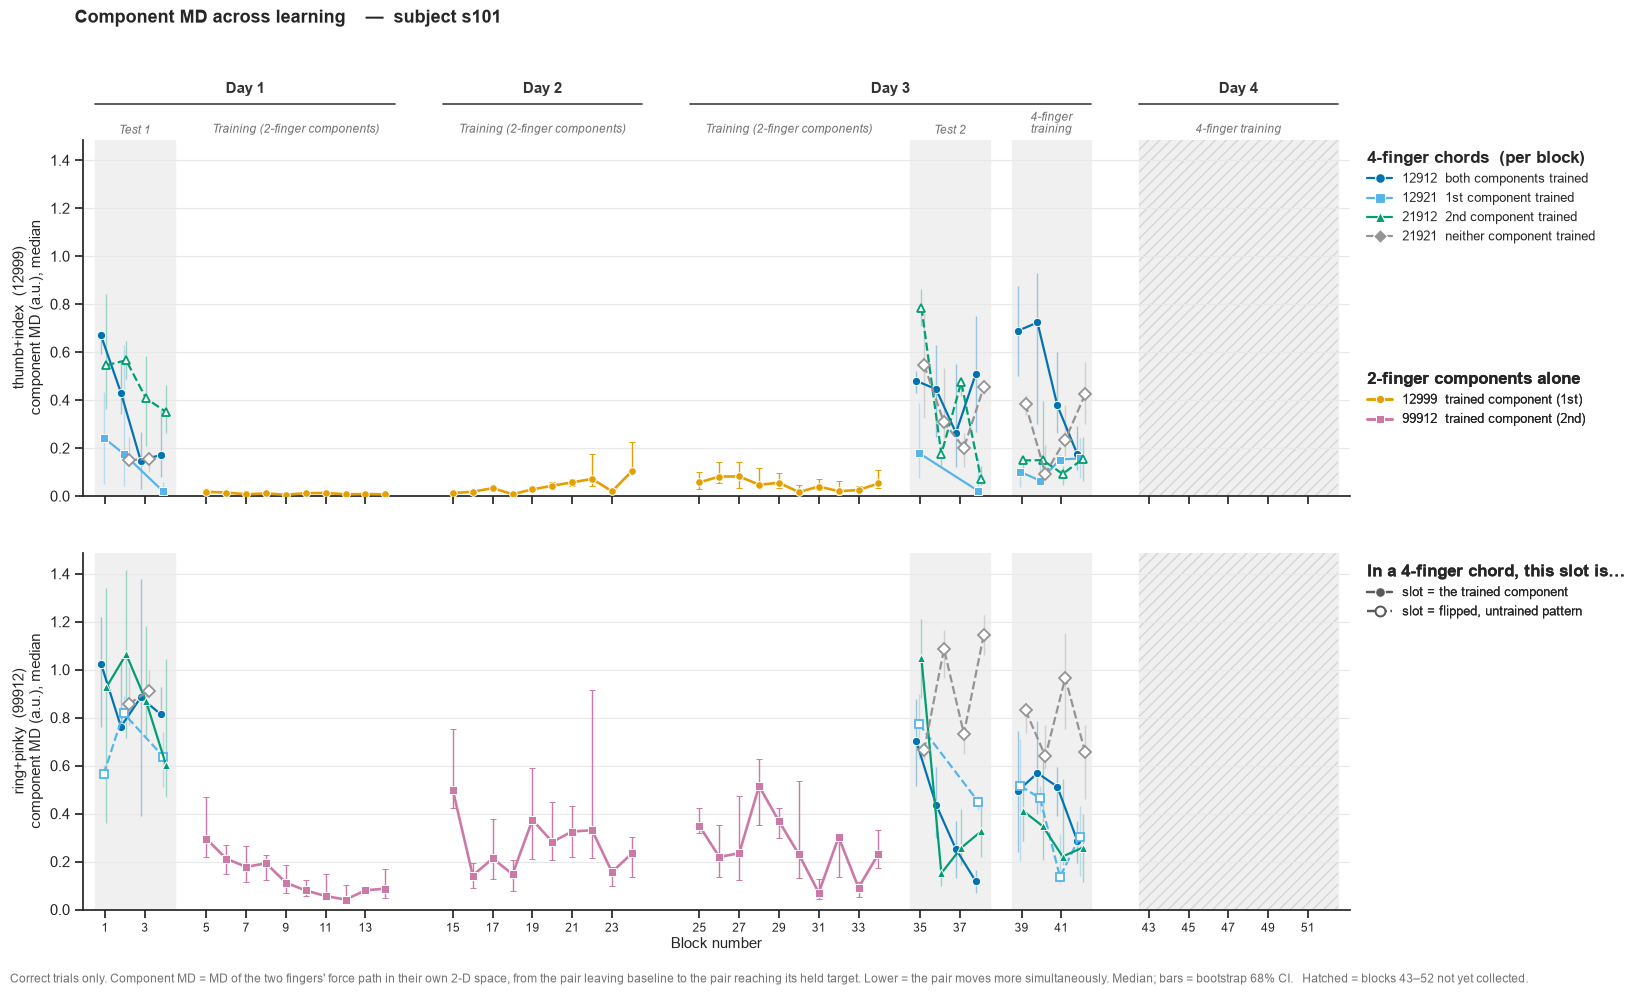

wrote figures/s101/component_md/01_component_md.png


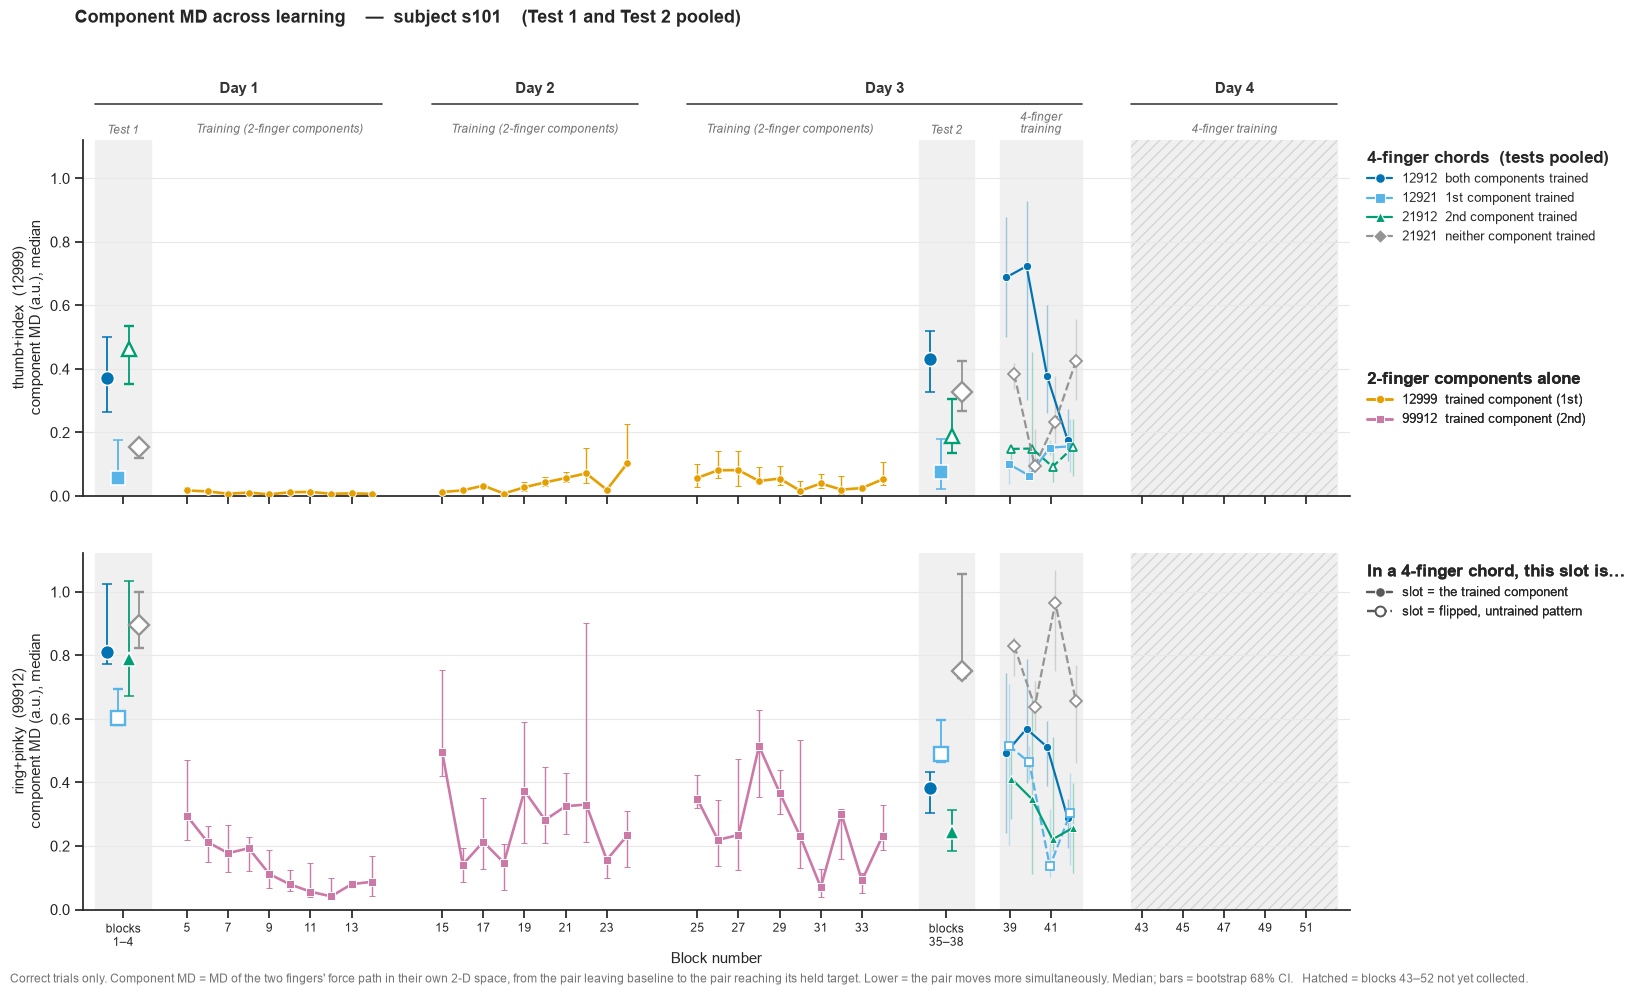

wrote figures/s101/component_md/01_component_md_pooled.png


In [3]:
dodge = dict(zip(TESTED, np.linspace(-0.2, 0.2, len(TESTED))))
dodge_pooled = dict(zip(TESTED, np.linspace(-0.78, 0.78, len(TESTED))))


def style(c, slot):
    """Filled + solid if `slot` of chord c is the trained component, else hollow + dashed."""
    if roles.contains(c, slot):
        return dict(color=COLOR[c], marker=MARKER[c], mfc=COLOR[c], mec="white", mew=.7, ls="-")
    return dict(color=COLOR[c], marker=MARKER[c], mfc="white", mec=COLOR[c], mew=1.3, ls="--")




for pool_tests in (False, True):
    segs = timeline.layout(pool_tests)
    fig, axes = plt.subplots(2, 1, figsize=(17, 10), sharex=True, sharey=True)

    for ax, slot in zip(axes, SLOTS):
        timeline.draw_background(ax, segs, COLLECTED)
        comp = roles.component[slot]
        d_slot = cmd[cmd.slot == roles.slot_name(slot)]

        for seg in segs:
            four = seg["kind"] == "4f"
            for c in (TESTED if four else [comp]):
                d = d_slot[d_slot.chordID == c]
                st = style(c, slot)
                if seg["pooled"]:
                    v = d[d.BN.isin(seg["blocks"])].cMD.dropna()
                    if len(v):
                        m, e = median_ci(v, rng)
                        ax.errorbar(seg["center"] + dodge_pooled[c], m, yerr=np.reshape(e, (2, 1)),
                                    ms=10, lw=0,
                                    capsize=3.5, elinewidth=1.3, zorder=4,
                                    **{**st, "mew": st["mew"] + .4})
                    continue
                xs, ys, es = [], [], []
                for b in seg["blocks"]:
                    v = d[d.BN == b].cMD.dropna()
                    if len(v):
                        m, e = median_ci(v, rng)
                        xs.append(seg["x"][b] + (dodge[c] if four else 0)); ys.append(m); es.append(e)
                if not xs:
                    continue
                eb = ax.errorbar(xs, ys, yerr=np.array(es).T, ms=6 if four else 5.5,
                                 lw=1.6 if four else 1.9, capsize=0 if four else 2.5,
                                 elinewidth=1, zorder=4 if four else 3, **st)
                if four:                   # ~5 trials per point: keep the bars quiet
                    for coll in eb[2]:
                        coll.set_alpha(.35)

        ax.set_ylabel(f"{roles.slot_name(slot)}  ({comp})\ncomponent MD (a.u.), median", fontsize=11)
        ax.grid(axis="y", color="0.91", lw=.8); ax.set_axisbelow(True)

    axes[0].set_ylim(bottom=0)
    timeline.draw_axis(axes[0], segs, headers=True)
    timeline.draw_axis(axes[1], segs, headers=False)
    axes[1].set_xlabel("Block number", fontsize=11, labelpad=2)
    axes[0].tick_params(labelbottom=False)

    h_test = [Line2D([], [], color=COLOR[c], marker=MARKER[c], ms=7, lw=1.6,
                     mec="white", mew=.8, label=LABEL[c]) for c in TESTED]
    h_train = [Line2D([], [], color=COLOR[c], marker=MARKER[c], ms=6, lw=1.9,
                      mec="white", mew=.7, label=LABEL[c]) for c in TRAINED]
    h_style = [Line2D([], [], color="0.35", marker="o", ms=7, lw=1.6, mec="white", mew=.8,
                      label="slot = the trained component"),
               Line2D([], [], color="0.35", marker="o", ms=7, lw=1.6, ls="--", mfc="white",
                      mec="0.35", mew=1.3, label="slot = flipped, untrained pattern")]
    for handles, title, y, ax in [
            (h_test, "4-finger chords" + ("  (tests pooled)" if pool_tests else "  (per block)"),
             1.0, axes[0]),
            (h_train, "2-finger components alone", .38, axes[0]),
            (h_style, "In a 4-finger chord, this slot is…", 1.0, axes[1])]:
        leg = ax.legend(handles=handles, title=title, loc="upper left",
                        bbox_to_anchor=(1.005, y), frameon=False, fontsize=9, labelspacing=.5)
        leg._legend_box.align = "left"; leg.get_title().set_fontweight("bold")
        ax.add_artist(leg)

    fig.text(.012, .012,
             "Correct trials only. Component MD = MD of the two fingers' force path in their own "
             "2-D space, from the pair leaving baseline to the pair reaching its held target. "
             "Lower = the pair moves more simultaneously. "
             "Median; bars = bootstrap 68% CI."
             + timeline.missing_note(SN, COLLECTED), fontsize=8.5, color="0.45", ha="left")
    fig.suptitle(f"Component MD across learning    —  subject s{SN}"
                 + ("    (Test 1 and Test 2 pooled)" if pool_tests else ""),
                 fontsize=13, fontweight="bold", x=.05, y=.985, ha="left", color="0.15")
    sns.despine(fig=fig)
    fig.subplots_adjust(left=.055, right=.80, top=.855, bottom=.085, hspace=.16)
    fname = "01_component_md" + ("_pooled" if pool_tests else "") + ".png"
    fig.savefig(FIG_DIR / fname, dpi=200, facecolor="white")
    plt.show()
    print(f"wrote {(FIG_DIR / fname).relative_to(ROOT)}")

## Each 4-finger session, chord by chord

Every trial of every 4-finger session, one panel per slot, the chords in which the slot is
the trained component on the left. The dashed line is the component's own median in the
last four training blocks, the dotted one in the first four: how synchronous the pair is
when produced alone, early and late in training.

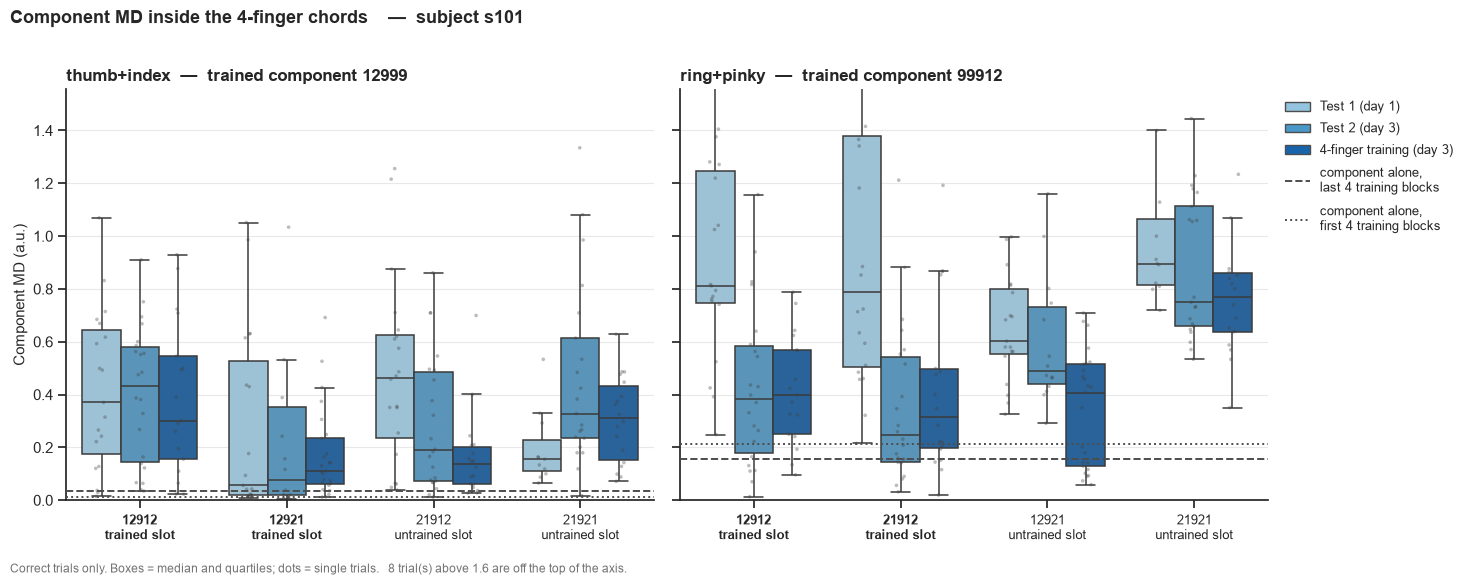

wrote figures/s101/component_md/02_sessions_by_chord.png


In [4]:
SESSIONS = [f"{s['name']} (day {s['day']})" for s in SEGMENTS if s["kind"] == "4f"]
SESSIONS = [s for s in SESSIONS if (cmd.session == s).any()]          # only collected ones
SESSION_PAL = dict(zip(SESSIONS, sns.color_palette("Blues", len(SESSIONS) + 1)[1:]))

four = cmd[cmd.kind == "4f"]
alone = cmd[cmd.kind == "2f"]
fig, axes = plt.subplots(1, len(SLOTS), figsize=(7.4 * len(SLOTS), 5.8), sharey=True)

for ax, slot in zip(axes, SLOTS):
    name, comp = roles.slot_name(slot), roles.component[slot]
    d = four[four.slot == name]
    order = sorted(TESTED, key=lambda c: (not roles.contains(c, slot), roles.role(c)))
    sns.boxplot(data=d, x="chordID", y="cMD", hue="session", order=order,
                hue_order=SESSIONS, palette=SESSION_PAL, width=.78, fliersize=0,
                linewidth=1.1, ax=ax)
    sns.stripplot(data=d, x="chordID", y="cMD", hue="session", order=order,
                  hue_order=SESSIONS, dodge=True, palette={s: "0.25" for s in SESSIONS},
                  size=2.6, alpha=.35, legend=False, ax=ax)
    for blocks, ls in [(TRAIN_LATE, "--"), (TRAIN_EARLY, ":")]:
        ref = alone[(alone.slot == name) & alone.BN.isin(blocks)].cMD.median()
        ax.axhline(ref, color="0.3", ls=ls, lw=1.4, zorder=5)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f"{c}\n{'trained' if roles.contains(c, slot) else 'untrained'} slot"
                        for c in order], fontsize=9.5)
    for lab, c in zip(ax.get_xticklabels(), order):
        lab.set_fontweight("bold" if roles.contains(c, slot) else "normal")
    ax.set_xlabel("")
    ax.set_ylabel("Component MD (a.u.)", fontsize=11)
    ax.set_title(f"{name}  —  trained component {comp}", loc="left",
                 fontsize=12, fontweight="bold")
    ax.grid(axis="y", color="0.91", lw=.8); ax.set_axisbelow(True)
    if ax.legend_:
        ax.legend_.remove()

top = np.nanpercentile(four.cMD, 97) * 1.15      # keep the boxes readable; see footnote
axes[0].set_ylim(0, top)
n_clip = int((four.cMD > top).sum())

h = [plt.Rectangle((0, 0), 1, 1, fc=SESSION_PAL[s], ec="0.3", label=s) for s in SESSIONS]
h += [Line2D([], [], color="0.3", ls="--", lw=1.4, label="component alone,\nlast 4 training blocks"),
      Line2D([], [], color="0.3", ls=":", lw=1.4, label="component alone,\nfirst 4 training blocks")]
axes[-1].legend(handles=h, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1),
                fontsize=9, labelspacing=.7)
fig.suptitle(f"Component MD inside the 4-finger chords    —  subject s{SN}",
             fontsize=13, fontweight="bold", x=.01, ha="left", color="0.15")
fig.text(.01, .01, "Correct trials only. Boxes = median and quartiles; dots = single trials."
         + (f"   {n_clip} trial(s) above {top:.1f} are off the top of the axis." if n_clip else ""),
         fontsize=8.5, color="0.45", ha="left")
sns.despine(fig=fig)
plt.tight_layout(rect=(0, .03, 1, .97))
plt.savefig(FIG_DIR / "02_sessions_by_chord.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print(f"wrote {(FIG_DIR / '02_sessions_by_chord.png').relative_to(ROOT)}")

## Statistics

Permutation test on the difference of medians (two-sided, trials shuffled between the
two sessions) for
each chord × slot, Test 1 against each later session. With ~20 trials per cell and a
heavy-tailed measure these are indicative only.

In [5]:
def perm(a, b, n=20000):
    """Two-sided permutation test on the difference of medians (a - b)."""
    obs = np.median(a) - np.median(b)
    pool = np.concatenate([a, b])
    shuffled = np.array([rng.permutation(pool) for _ in range(n)])
    null = np.median(shuffled[:, :len(a)], axis=1) - np.median(shuffled[:, len(a):], axis=1)
    return obs, np.mean(np.abs(null) >= abs(obs))


print("Component alone (training), median component MD")
print("=" * 78)
for slot in SLOTS:
    name = roles.slot_name(slot)
    for label, blocks in [("first 4 blocks", TRAIN_EARLY), ("last 4 blocks", TRAIN_LATE)]:
        v = alone[(alone.slot == name) & alone.BN.isin(blocks)].cMD
        print(f"  {name:<12} {roles.component[slot]}   {label:<15} {v.median():.3f}  (n = {len(v)})")

base = SESSIONS[0]
print(f"\nInside the 4-finger chords: {base} vs each later session")
print("=" * 78)
for slot in SLOTS:
    name = roles.slot_name(slot)
    print(f"\n  {name}")
    for c in sorted(TESTED, key=lambda c: (not roles.contains(c, slot), roles.role(c))):
        d = four[(four.slot == name) & (four.chordID == c)]
        a = d[d.session == base].cMD.dropna().to_numpy()
        tag = "trained  " if roles.contains(c, slot) else "untrained"
        for later in SESSIONS[1:]:
            b = d[d.session == later].cMD.dropna().to_numpy()
            if len(a) < 3 or len(b) < 3:
                continue
            o, p = perm(a, b)
            print(f"    {c} {tag}  -> {later:<28} {np.median(a):5.2f} -> {np.median(b):5.2f}   "
                  f"diff = {-o:+5.2f}   p = {p:.4f} {'*' if p < .05 else 'ns'}   "
                  f"(n = {len(a)}, {len(b)})")

Component alone (training), median component MD
  thumb+index  12999   first 4 blocks  0.011  (n = 37)
  thumb+index  12999   last 4 blocks   0.034  (n = 39)
  ring+pinky   99912   first 4 blocks  0.212  (n = 42)
  ring+pinky   99912   last 4 blocks   0.155  (n = 40)

Inside the 4-finger chords: Test 1 (day 1) vs each later session

  thumb+index
    12912 trained    -> Test 2 (day 3)                0.37 ->  0.43   diff = +0.06   p = 0.8299 ns   (n = 19, 22)
    12912 trained    -> 4-finger training (day 3)     0.37 ->  0.30   diff = -0.07   p = 0.8604 ns   (n = 19, 17)
    12921 trained    -> Test 2 (day 3)                0.06 ->  0.08   diff = +0.02   p = 0.9227 ns   (n = 19, 14)
    12921 trained    -> 4-finger training (day 3)     0.06 ->  0.11   diff = +0.05   p = 0.3725 ns   (n = 19, 25)
    21912 untrained  -> Test 2 (day 3)                0.46 ->  0.19   diff = -0.28   p = 0.0663 ns   (n = 20, 22)
    21912 untrained  -> 4-finger training (day 3)     0.46 ->  0.14   diff = -0.3

    21921 untrained  -> 4-finger training (day 3)     0.16 ->  0.31   diff = +0.16   p = 0.1514 ns   (n = 11, 18)

  ring+pinky
    12912 trained    -> Test 2 (day 3)                0.81 ->  0.38   diff = -0.43   p = 0.0018 *   (n = 19, 22)
    12912 trained    -> 4-finger training (day 3)     0.81 ->  0.40   diff = -0.41   p = 0.0001 *   (n = 19, 17)
    21912 trained    -> Test 2 (day 3)                0.79 ->  0.25   diff = -0.54   p = 0.0001 *   (n = 20, 22)
    21912 trained    -> 4-finger training (day 3)     0.79 ->  0.32   diff = -0.47   p = 0.0043 *   (n = 20, 18)
    12921 untrained  -> Test 2 (day 3)                0.60 ->  0.49   diff = -0.11   p = 0.2964 ns   (n = 19, 14)
    12921 untrained  -> 4-finger training (day 3)     0.60 ->  0.41   diff = -0.19   p = 0.0088 *   (n = 19, 25)
    21921 untrained  -> Test 2 (day 3)                0.90 ->  0.75   diff = -0.15   p = 0.3814 ns   (n = 11, 21)


    21921 untrained  -> 4-finger training (day 3)     0.90 ->  0.77   diff = -0.13   p = 0.0634 ns   (n = 11, 18)
